# 03 Exploratory Data Analysis (BUSA 310 Project 1)

**Input:** `data/processed/philly_sf_sales_clean.csv` (output of 02_data_cleaning).
**Scope (group decision, 2026-10-12):** whole city, ZIP code used as the location input.
**Questions (chosen by the group):**
1. How are sale prices distributed?
2. How does sale price relate to living area?
3. How do sale prices differ across ZIP codes?
4. How did prices and sales volume move month to month, 2024 to 2026?

Each chart is saved to `figures/`. The cells print the numbers behind each chart; the written interpretation is the group's.

AI use note: chart code drafted with Claude (Claude Code); see AI Use Log.

## 0. Setup

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
os.makedirs("figures", exist_ok=True)

CLEAN_PATH = "data/processed/philly_sf_sales_clean.csv"

# Colab starts empty each session: if the cleaned file isn't there, ask to upload it
if not os.path.exists(CLEAN_PATH):
    from google.colab import files
    os.makedirs("data/processed", exist_ok=True)
    print("Upload philly_sf_sales_clean.csv")
    uploaded = files.upload()
    name = list(uploaded.keys())[0]
    os.replace(name, CLEAN_PATH)

df = pd.read_csv(CLEAN_PATH, low_memory=False,
                 dtype={"zip_code": str, "parcel_number": str, "census_tract": str},
                 parse_dates=["sale_date"])

# Chart style: one hue for single-series charts, thin marks, light grid
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
})
dollars = mtick.FuncFormatter(lambda x, _: f"${x/1e6:.1f}M" if x >= 1e6 else f"${x/1e3:.0f}K")
SOURCE = r"Source: City of Philadelphia OPA Properties, single family sales Jan 2024 to Sep 2026 over \$25,000"

## Chart 1. How are sale prices distributed?
Left: dollars on a normal scale. Right: the same data on a log scale (each tick is 10x the one before),
which spreads out the long tail of expensive homes. Dashed line = median.

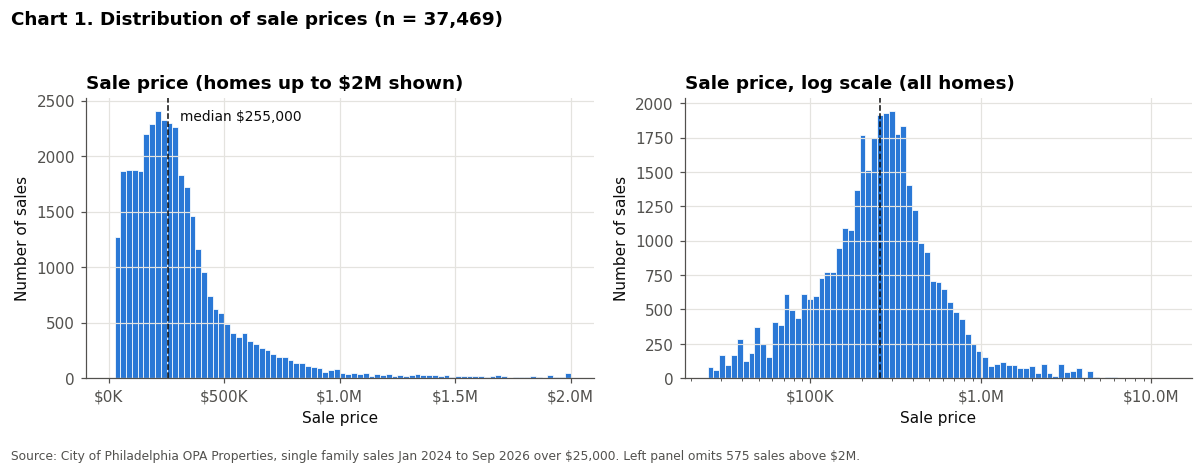

count        37,469
mean        354,561
std         462,643
min          25,001
10%          80,000
25%         155,000
50%         255,000
75%         385,000
90%         630,000
99%       2,600,000
max      12,741,000
skewness: 6.96 | skewness of log(price): 0.11


In [5]:
price = df["sale_price"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(price, bins=np.linspace(0, 2_000_000, 81), color=BLUE, edgecolor="white", linewidth=0.5)
axes[0].set_title(r"Sale price (homes up to \$2M shown)")
axes[0].xaxis.set_major_locator(mtick.MultipleLocator(500_000))
axes[0].xaxis.set_major_formatter(dollars)
axes[1].hist(price, bins=np.logspace(np.log10(25_000), np.log10(price.max()), 80), color=BLUE, edgecolor="white", linewidth=0.5)
axes[1].set_xscale("log")
axes[1].set_title("Sale price, log scale (all homes)")
axes[1].xaxis.set_major_formatter(dollars)
for ax in axes:
    ax.axvline(price.median(), color=INK, linestyle="--", linewidth=1)
    ax.set_xlabel("Sale price")
    ax.set_ylabel("Number of sales")
axes[0].annotate(rf"median \${price.median():,.0f}", xy=(price.median(), axes[0].get_ylim()[1] * 0.92),
                 xytext=(8, 0), textcoords="offset points", color=INK, fontsize=9)
fig.suptitle(f"Chart 1. Distribution of sale prices (n = {len(df):,})", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.text(0.01, -0.04, SOURCE + rf". Left panel omits {int((price > 2_000_000).sum()):,} sales above \$2M.", fontsize=8, color=INK2)
fig.savefig("figures/chart1_price_distribution.png")
plt.show()

print(price.describe(percentiles=[.1, .25, .5, .75, .9, .99]).apply(lambda v: f"{v:,.0f}").to_string())
print("skewness:", round(price.skew(), 2), "| skewness of log(price):", round(np.log(price).skew(), 2))

**Questions for the group (answer in your own words):**
- Is the distribution symmetric or skewed? What does the gap between mean and median tell you?
- Does the log view change how you would model price (for example, predicting log(price))?

## Chart 2. How does sale price relate to living area?
Both axes on a log scale. Flagged rows from cleaning are colored so the group can see where they sit:
bundled sales (several parcels sold together at one price) and vacant lots. Rows with 0 or missing living area cannot be drawn on a log axis and are counted below.

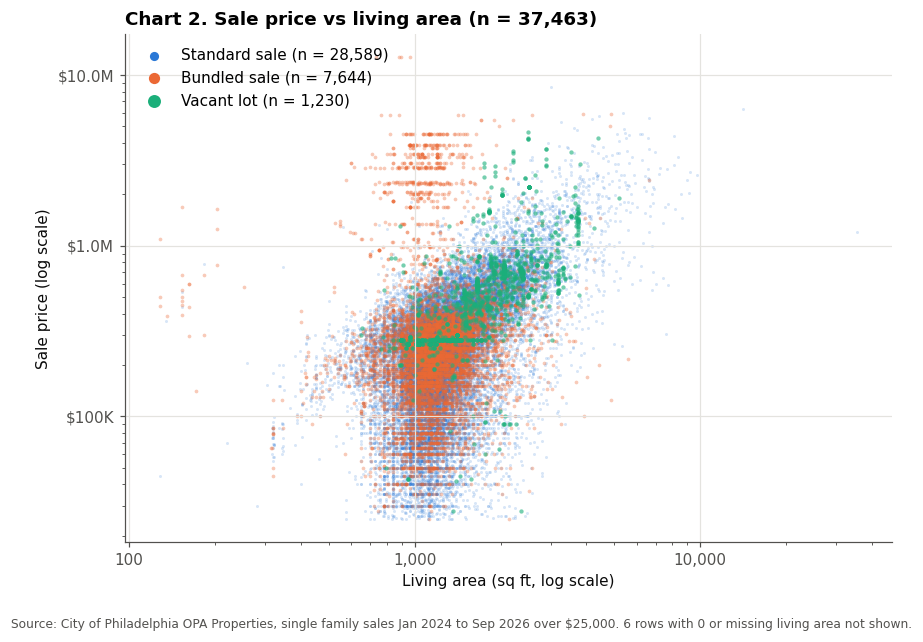

               sale_price  total_livable_area
group                                        
Bundled sale     245000.0              1174.0
Standard sale    251000.0              1224.0
Vacant lot       499900.0              1704.0
correlation, log(price) vs log(area), standard sales only: 0.519


In [6]:
plot = df[df["total_livable_area"] > 0].copy()
plot["group"] = np.select([plot["flag_vacant"], plot["bundle_size"] > 1], ["Vacant lot", "Bundled sale"], "Standard sale")
order = [("Standard sale", BLUE, 4, 0.18), ("Bundled sale", ORANGE, 6, 0.35), ("Vacant lot", AQUA, 8, 0.6)]

fig, ax = plt.subplots(figsize=(9, 6))
for name, color, size, alpha in order:
    g = plot[plot["group"] == name]
    ax.scatter(g["total_livable_area"], g["sale_price"], s=size, color=color, alpha=alpha,
               linewidths=0, label=f"{name} (n = {len(g):,})")
ax.set_xscale("log"); ax.set_yscale("log")
ax.yaxis.set_major_formatter(dollars)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.set_xlabel("Living area (sq ft, log scale)")
ax.set_ylabel("Sale price (log scale)")
ax.set_title(f"Chart 2. Sale price vs living area (n = {len(plot):,})")
leg = ax.legend(loc="upper left", frameon=False, markerscale=3)
for h in leg.legend_handles: h.set_alpha(1)
fig.text(0.01, -0.02, SOURCE + f". {len(df) - len(plot):,} rows with 0 or missing living area not shown.", fontsize=8, color=INK2)
fig.savefig("figures/chart2_price_vs_living_area.png")
plt.show()

print(plot.groupby("group")[["sale_price", "total_livable_area"]].median().round(0).to_string())
print("correlation, log(price) vs log(area), standard sales only:",
      round(np.corrcoef(np.log(plot.loc[plot.group == "Standard sale", "total_livable_area"]),
                        np.log(plot.loc[plot.group == "Standard sale", "sale_price"]))[0, 1], 3))

**Questions for the group:**
- How strong does the relationship look for standard sales? Is it a straight line on the log scale?
- Where do bundled sales and vacant lots sit compared with standard sales? Does that change your keep or drop decision for them?
- Correlation is not causation: what else could make bigger homes sell for more?

## Chart 3. How do sale prices differ across ZIP codes?
Box plot per ZIP, sorted by median price. Box = middle 50% of sales, line inside = median, whiskers = 10th to 90th percentile
(points beyond them are hidden to keep the chart readable). Sales count shown next to each ZIP.
Caution: ZIPs differ in home size and type, so a higher median does not mean the same house costs more there.

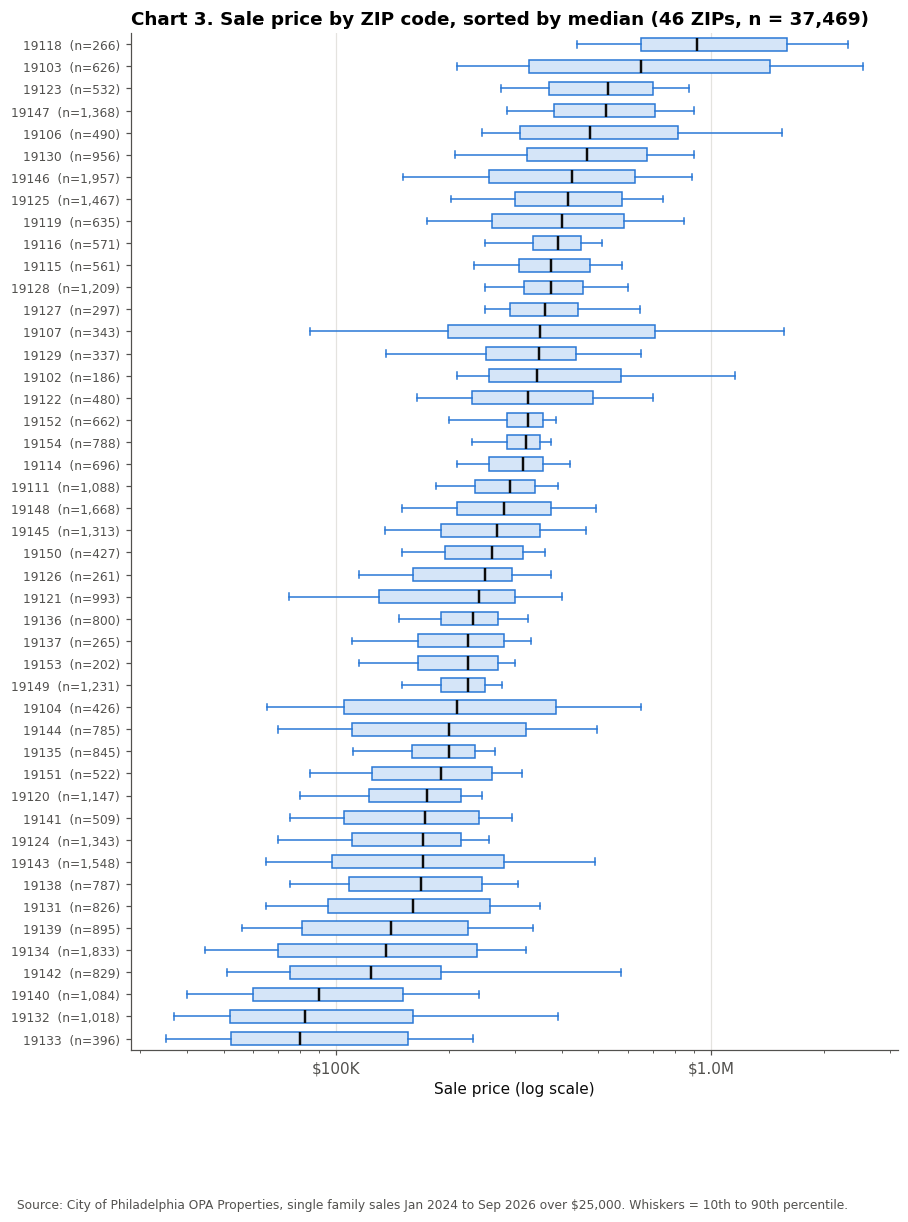

          sales    median
zip_code                 
19118       266  $915,000
19103       626  $650,000
19123       532  $530,000
19147      1368  $525,000
19106       490  $475,000
19130       956  $466,750
19146      1957  $425,000
19125      1467  $415,000
19119       635  $400,000
19116       571  $390,000
19115       561  $375,000
19128      1209  $375,000
19127       297  $359,500
19107       343  $350,000
19129       337  $347,500
19102       186  $343,000
19122       480  $325,000
19152       662  $323,750
19154       788  $320,000
19114       696  $315,000
19111      1088  $290,000
19148      1668  $280,000
19145      1313  $267,500
19150       427  $260,000
19126       261  $250,000
19121       993  $239,900
19136       800  $231,750
19137       265  $225,000
19149      1231  $225,000
19153       202  $225,000
19104       426  $209,950
19135       845  $200,000
19144       785  $200,000
19151       522  $190,000
19120      1147  $175,000
19141       509  $172,000
19143      1

In [7]:
zip_stats = df.groupby("zip_code")["sale_price"].agg(sales="size", median="median").sort_values("median")
zips = zip_stats.index.tolist()
data = [df.loc[df["zip_code"] == z, "sale_price"].values for z in zips]

fig, ax = plt.subplots(figsize=(9, 12))
ax.boxplot(data, vert=False, whis=(10, 90), showfliers=False, widths=0.6, patch_artist=True,
           boxprops=dict(facecolor="#d5e5f8", edgecolor=BLUE, linewidth=1),
           medianprops=dict(color=INK, linewidth=1.6),
           whiskerprops=dict(color=BLUE, linewidth=1), capprops=dict(color=BLUE, linewidth=1))
ax.set_yticks(range(1, len(zips) + 1))
ax.set_yticklabels([f"{z}  (n={zip_stats.loc[z, 'sales']:,})" for z in zips], fontsize=8)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(dollars)
ax.set_xlabel("Sale price (log scale)")
ax.grid(axis="y", visible=False)
ax.set_title(f"Chart 3. Sale price by ZIP code, sorted by median ({len(zips)} ZIPs, n = {len(df):,})")
fig.text(0.01, -0.01, SOURCE + ". Whiskers = 10th to 90th percentile.", fontsize=8, color=INK2)
fig.savefig("figures/chart3_price_by_zip.png")
plt.show()

print(zip_stats.sort_values("median", ascending=False).assign(median=lambda t: t["median"].map("${:,.0f}".format)).to_string())

**Questions for the group:**
- How large is the gap between the cheapest and most expensive ZIPs? Is ZIP likely to matter more or less than living area?
- Which ZIPs have few sales, and how much should you trust a prediction there?
- Is the difference between ZIPs about location, or about the kind of homes that sell there? (Check median living area by ZIP.)

## Chart 4. How did prices and sales volume move month to month?
Two panels on a shared time axis (one measure per axis, not a dual axis chart).
Top: median sale price per month. Bottom: number of sales per month.
September 2026 is a partial month (data ends 2026-09-02) and is excluded.
August 2026 has far fewer sales than any other month, likely because recent sales are not yet recorded; its median rests on a small sample.
The price axis does not start at $0, so month to month changes look larger than they are in percentage terms.

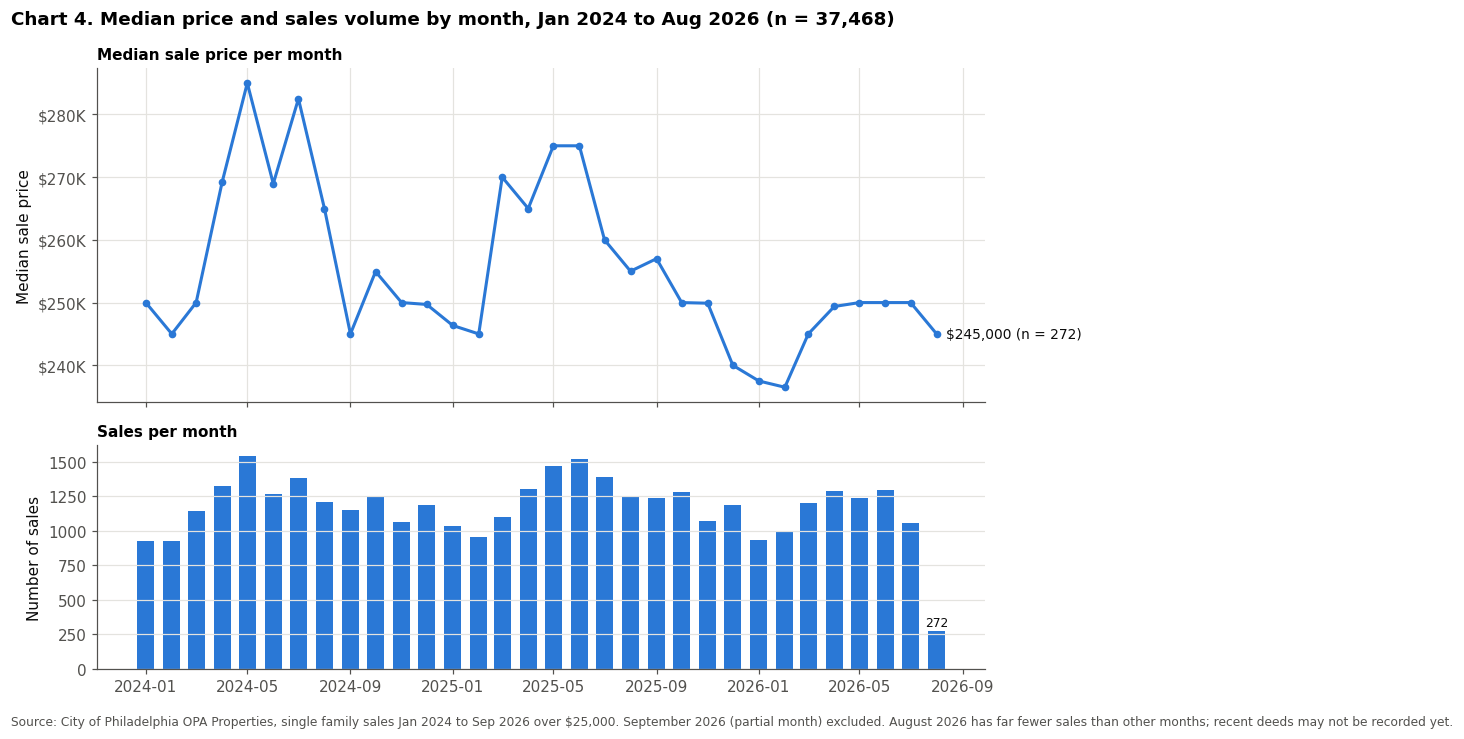

         sales    median
month                   
2024-01    925  $250,000
2024-02    926  $245,000
2024-03   1141  $250,000
2024-04   1323  $269,200
2024-05   1543  $285,000
2024-06   1268  $268,950
2024-07   1382  $282,500
2024-08   1213  $264,999
2024-09   1149  $245,000
2024-10   1246  $254,950
2024-11   1066  $250,000
2024-12   1185  $249,700
2025-01   1037  $246,350
2025-02    955  $245,000
2025-03   1104  $270,000
2025-04   1301  $265,000
2025-05   1469  $275,000
2025-06   1520  $275,000
2025-07   1391  $260,000
2025-08   1256  $255,000
2025-09   1240  $257,000
2025-10   1284  $249,998
2025-11   1069  $249,900
2025-12   1191  $240,000
2026-01    931  $237,500
2026-02    996  $236,500
2026-03   1201  $245,000
2026-04   1292  $249,375
2026-05   1239  $250,000
2026-06   1294  $250,000
2026-07   1059  $250,000
2026-08    272  $245,000


In [8]:
monthly = (df.assign(month=df["sale_date"].dt.to_period("M"))
             .groupby("month")["sale_price"].agg(sales="size", median="median"))
monthly = monthly[monthly.index < pd.Period("2026-09", "M")]
x = monthly.index.to_timestamp()

fig, (top, bot) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
top.plot(x, monthly["median"], color=BLUE, linewidth=2, marker="o", markersize=4)
top.yaxis.set_major_formatter(dollars)
top.set_ylabel("Median sale price")
top.set_title("Median sale price per month", fontsize=10)
top.annotate(rf"\${monthly['median'].iloc[-1]:,.0f} (n = {monthly['sales'].iloc[-1]:,})", xy=(x[-1], monthly["median"].iloc[-1]),
             xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=INK)
bot.bar(x, monthly["sales"], width=20, color=BLUE)
bot.set_ylabel("Number of sales")
bot.annotate(f"{monthly['sales'].iloc[-1]:,}", xy=(x[-1], monthly["sales"].iloc[-1]), xytext=(0, 3),
             textcoords="offset points", ha="center", fontsize=8, color=INK)
bot.set_title("Sales per month", fontsize=10)
bot.grid(axis="x", visible=False)
fig.suptitle(f"Chart 4. Median price and sales volume by month, Jan 2024 to Aug 2026 (n = {int(monthly['sales'].sum()):,})",
             x=0.01, ha="left", fontweight="bold")
fig.text(0.01, -0.02, SOURCE + ". September 2026 (partial month) excluded. August 2026 has far fewer sales than other months; recent deeds may not be recorded yet.", fontsize=8, color=INK2)
fig.tight_layout()
fig.savefig("figures/chart4_price_over_time.png")
plt.show()

print(monthly.assign(median=monthly["median"].map("${:,.0f}".format)).to_string())

**Questions for the group:**
- Is there a trend or a seasonal pattern (for example, spring and summer peaks)?
- Should sale month or year be a model input, so a 2024 sale is not treated the same as a 2026 sale?
- Interest rates moved during this period. That is not in your data: how would you mention it as a limitation?

## Group notes (write your own)
- What the four charts show:
- Decisions they changed (bundles, vacant lots, log price, time input):
